In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle, Patch
from matplotlib.colors import LinearSegmentedColormap

# ============ 全局样式：贴近 Excel 的干净白底风格 ============
plt.rcParams.update({
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans'],
    'axes.unicode_minus': False,      # 正常显示负号
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#DADCE0',
    'axes.labelcolor': '#3C4043',
    'xtick.color': '#5F6368',
    'ytick.color': '#5F6368',
    'text.color': '#202124',
})

C_MAIN = '#2F6BFF'      # 主色（蓝）
C_DEEP = '#0E2A6B'      # 渐变深端
C_LIGHT = '#7FC0FF'     # 渐变浅端
C_WARM = '#FF8A3D'      # 强调色（橙）
C_GRAY = '#C9D2E0'      # 辅助灰
C_TEXT = '#202124'
C_SUB = '#8A94A6'

SAVE = False            # ← 改成 True 即可批量导出 PNG
OUT_DIR = 'charts_png'


# ============ 通用工具函数 ============
def unit_px(ax):
    """返回坐标轴 1 个数据单位对应的屏幕像素，用于把圆角画成正圆。"""
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    return bb.width / max(abs(x1 - x0), 1e-9), bb.height / max(abs(y1 - y0), 1e-9)


def rounded_path(x, y, w, h, rx=0.0, ry=None, corners='top', ax=None):
    """生成圆角矩形路径。rx 为 x 方向半径，ry 由屏幕像素换算，保证圆角不被拉扁。"""
    if ry is None:
        if ax is not None and rx > 0:
            px_x, px_y = unit_px(ax)
            ry = rx * px_x / px_y
        else:
            ry = rx
    rx = min(rx, abs(w) / 2)
    ry = min(ry, abs(h))
    k = 0.5523
    V, C = [], []

    def mv(p):
        V.append(p); C.append(Path.MOVETO)

    def ln(p):
        V.append(p); C.append(Path.LINETO)

    def cu(p1, p2, p3):
        V.extend([p1, p2, p3]); C.extend([Path.CURVE4] * 3)

    x2, y2 = x + w, y + h
    rb = ry if corners == 'all' else 0.0
    mv((x, y + rb))
    ln((x, y2 - ry))
    cu((x, y2 - ry + k * ry), (x + rx - k * rx, y2), (x + rx, y2))
    ln((x2 - rx, y2))
    cu((x2 - rx + k * rx, y2), (x2, y2 - ry + k * ry), (x2, y2 - ry))
    ln((x2, y + rb))
    if rb:
        cu((x2, y + rb - k * rb), (x2 - rx + k * rx, y), (x2 - rx, y))
        ln((x + rx, y))
        cu((x + rx - k * rx, y), (x, y + rb - k * rb), (x, y + rb))
    else:
        ln((x, y))
    V.append(V[0]); C.append(Path.CLOSEPOLY)
    return Path(V, C)


def gradient_fill(ax, path, c1, c2, extent, direction='v', zorder=3, alpha=1.0):
    """用 imshow 生成线性渐变，再用路径裁剪 —— 这是「渐变柱形图」的关键。"""
    cmap = LinearSegmentedColormap.from_list('grad', [c1, c2])
    g = np.linspace(0, 1, 256)
    img = g.reshape(-1, 1) if direction == 'v' else g.reshape(1, -1)
    im = ax.imshow(img, extent=extent, origin='lower', aspect='auto',
                   cmap=cmap, alpha=alpha, zorder=zorder, interpolation='bilinear')
    clip = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(clip)
    im.set_clip_path(clip)
    return im


def vbar(ax, x, h, w=0.55, c1=C_DEEP, c2=C_LIGHT, bottom=0, r=0.08, zorder=3, alpha=1.0):
    """竖向渐变柱（圆角在顶部）。"""
    p = rounded_path(x - w / 2, bottom, w, h - bottom, rx=r, corners='top', ax=ax)
    return gradient_fill(ax, p, c1, c2, (x - w / 2, x + w / 2, bottom, h), 'v', zorder, alpha)


def hbar_gradient(ax, y, v, left=0, h=0.55, c1=C_DEEP, c2=C_LIGHT, zorder=3, alpha=1.0):
    """横向渐变条（用于条形图）。"""
    p = Path([(left, y - h / 2), (left + v, y - h / 2), (left + v, y + h / 2), (left, y + h / 2), (left, y - h / 2)],
             [Path.MOVETO, Path.LINETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY])
    return gradient_fill(ax, p, c1, c2, (left, left + v, y - h / 2, y + h / 2), 'h', zorder, alpha)


def clean_ax(ax, grid='y', left=True, bottom=True):
    """去掉多余边框，只保留干净的网格线。"""
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_visible(left)
    ax.spines['bottom'].set_visible(bottom)
    if left:
        ax.spines['left'].set_color('#DADCE0')
    if bottom:
        ax.spines['bottom'].set_color('#C9CED6')
    if grid:
        ax.grid(axis=grid, color='#EEF1F6', linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0, pad=8)


def titles(ax, title, sub, pad=30):
    """左对齐主标题 + 灰色副标题，Excel 图表的常见排版。"""
    ax.set_title(title, loc='left', fontsize=17, fontweight='bold', color=C_TEXT, pad=pad)
    ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=10.5, color=C_SUB)


def finish(fig, name):
    """统一收尾：按需导出 PNG 并显示。"""
    if SAVE:
        os.makedirs(OUT_DIR, exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, f'{name}.png'), bbox_inches='tight', facecolor='white')
    plt.show()

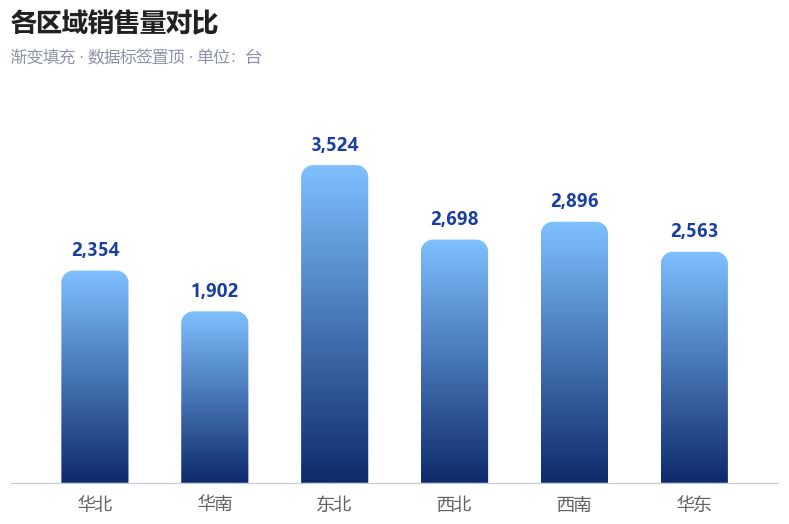

In [2]:
df1 = pd.DataFrame({'区域': ['华北', '华南', '东北', '西北', '西南', '华东'],
                    '销售量': [2354, 1902, 3524, 2698, 2896, 2563]})

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.set_xlim(-0.7, len(df1) - 0.3)
ax.set_ylim(0, df1['销售量'].max() * 1.28)

for i, v in enumerate(df1['销售量']):
    vbar(ax, i, v, w=0.56, c1=C_DEEP, c2=C_LIGHT, r=0.10)
    ax.text(i, v + df1['销售量'].max() * 0.035, f'{v:,}', ha='center', va='bottom',
            fontsize=11.5, fontweight='bold', color='#1A3FA0')

ax.set_xticks(range(len(df1)))
ax.set_xticklabels(df1['区域'], fontsize=11.5)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
titles(ax, '各区域销售量对比', '渐变填充 · 数据标签置顶 · 单位：台')
finish(fig, 'case01_gradient_bar')

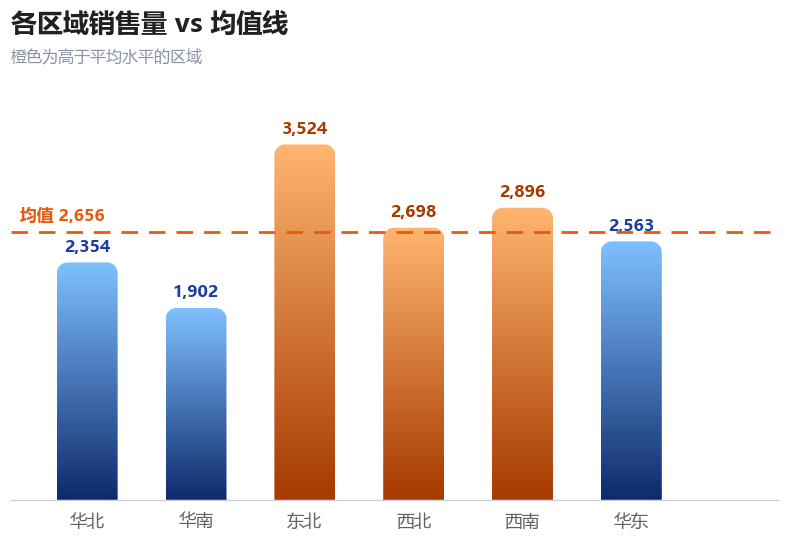

In [3]:
df2 = pd.DataFrame({'区域': ['华北', '华南', '东北', '西北', '西南', '华东'],
                    '销售量': [2354, 1902, 3524, 2698, 2896, 2563]})
avg = df2['销售量'].mean()

fig, ax = plt.subplots(figsize=(9, 5.0))
ax.set_xlim(-0.7, len(df2) + 0.35)
ax.set_ylim(0, 4200)

for i, v in enumerate(df2['销售量']):
    if v >= avg:
        vbar(ax, i, v, w=0.56, c1='#A63A00', c2='#FFB570', r=0.10)
        color = '#A63A00'
    else:
        vbar(ax, i, v, w=0.56, c1=C_DEEP, c2=C_LIGHT, r=0.10)
        color = '#1A3FA0'
    ax.text(i, v + 70, f'{v:,}', ha='center', va='bottom', fontsize=11, fontweight='bold', color=color)

ax.axhline(avg, color='#E8590C', lw=1.8, ls=(0, (6, 4)), zorder=5)
ax.text(-0.62, avg + 70, f'均值 {avg:,.0f}', fontsize=11, fontweight='bold',
        color='#E8590C', va='bottom', ha='left',
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85))

ax.set_xticks(range(len(df2)))
ax.set_xticklabels(df2['区域'], fontsize=11.5)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
titles(ax, '各区域销售量 vs 均值线', '橙色为高于平均水平的区域')
finish(fig, 'case02_bar_with_average')

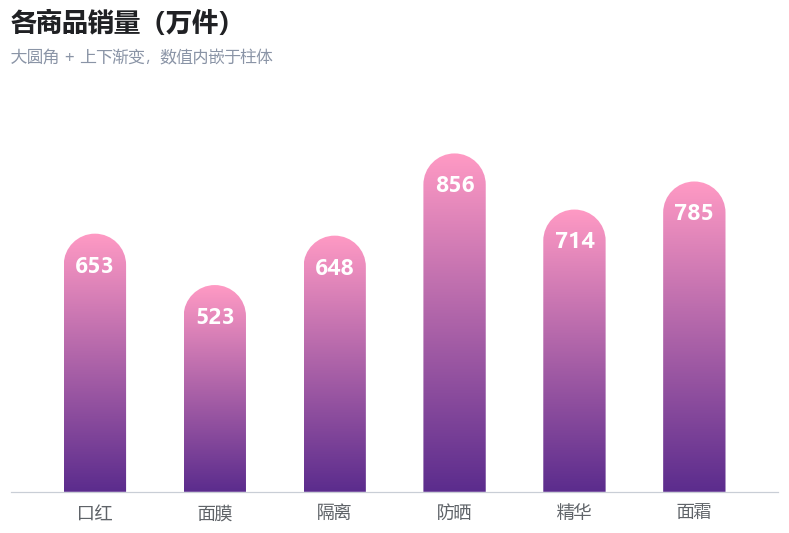

In [4]:
df3 = pd.DataFrame({'商品': ['口红', '面膜', '隔离', '防晒', '精华', '面霜'],
                    '销量': [653, 523, 648, 856, 714, 785]})

fig, ax = plt.subplots(figsize=(9, 4.9))
ax.set_xlim(-0.7, len(df3) - 0.3)
ax.set_ylim(0, 1050)

for i, v in enumerate(df3['销量']):
    vbar(ax, i, v, w=0.52, c1='#5B2C8D', c2='#FF9AC4', r=0.26)
    ax.text(i, v - 55, f'{v}', ha='center', va='top', fontsize=14, fontweight='bold', color='white')

ax.set_xticks(range(len(df3)))
ax.set_xticklabels(df3['商品'], fontsize=11.5)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
ax.set_ylim(0, 1050)
titles(ax, '各商品销量（万件）', '大圆角 + 上下渐变，数值内嵌于柱体')
finish(fig, 'case03_rounded_gradient_bar')

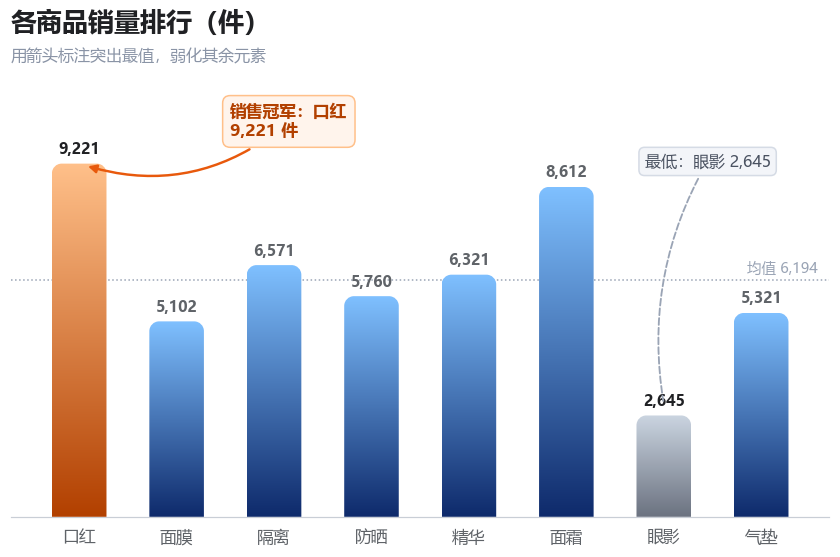

In [5]:
df4 = pd.DataFrame({'商品': ['口红', '面膜', '隔离', '防晒', '精华', '面霜', '眼影', '气垫'],
                    '销量': [9221, 5102, 6571, 5760, 6321, 8612, 2645, 5321]})

imax, imin = df4['销量'].idxmax(), df4['销量'].idxmin()

fig, ax = plt.subplots(figsize=(9.6, 5.2))
ax.set_xlim(-0.7, len(df4) - 0.3)
ax.set_ylim(0, 11500)

for i, v in enumerate(df4['销量']):
    if i == imax:
        vbar(ax, i, v, w=0.56, c1='#B24000', c2='#FFC08A', r=0.10)
    elif i == imin:
        vbar(ax, i, v, w=0.56, c1='#6B7280', c2='#CBD5E1', r=0.10)
    else:
        vbar(ax, i, v, w=0.56, c1=C_DEEP, c2=C_LIGHT, r=0.10)
    ax.text(i, v + 160, f'{v:,}', ha='center', va='bottom', fontsize=10,
            color='#5F6368' if i not in (imax, imin) else '#202124', fontweight='bold')

# 最高值弧形箭头标注
ax.annotate('销售冠军：口红\n9,221 件',
            xy=(imax, df4['销量'].iloc[imax]), xytext=(imax + 1.55, 10800),
            fontsize=11, fontweight='bold', color='#B24000', ha='left', va='top',
            bbox=dict(boxstyle='round,pad=0.45', fc='#FFF4EC', ec='#FFC08A', lw=1),
            arrowprops=dict(arrowstyle='-|>', color='#E8590C', lw=1.6,
                            connectionstyle='arc3,rad=-0.28', shrinkB=6))

# 最低值标注（走两根柱子之间的空隙，避免压住其它柱）
ax.annotate('最低：眼影 2,645', xy=(imin, df4['销量'].iloc[imin] + 300),
            xytext=(imin + 0.45, 9500),
            fontsize=10.5, color='#4A5261', ha='center', va='top',
            bbox=dict(boxstyle='round,pad=0.35', fc='#F3F5F9', ec='#D5DBE5', lw=1),
            arrowprops=dict(arrowstyle='-', color='#9AA4B5', lw=1.2, ls='--',
                            connectionstyle='arc3,rad=0.18', shrinkB=2))

ax.axhline(df4['销量'].mean(), color='#9AA4B5', lw=1, ls=':', zorder=1)
ax.text(len(df4) - 0.42, df4['销量'].mean() + 200, f'均值 {df4["销量"].mean():,.0f}',
        ha='right', fontsize=9.5, color='#9AA4B5')

ax.set_xticks(range(len(df4)))
ax.set_xticklabels(df4['商品'], fontsize=11)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
titles(ax, '各商品销量排行（件）', '用箭头标注突出最值，弱化其余元素')
finish(fig, 'case04_annotated_bar')

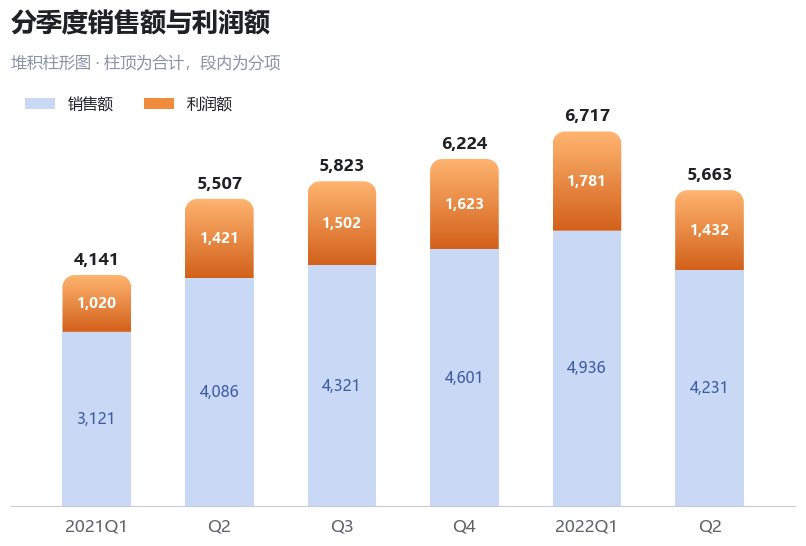

In [6]:
df5 = pd.DataFrame({'季度': ['2021Q1', 'Q2', 'Q3', 'Q4', '2022Q1', 'Q2'],
                    '销售额': [3121, 4086, 4321, 4601, 4936, 4231],
                    '利润额': [1020, 1421, 1502, 1623, 1781, 1432]})

fig, ax = plt.subplots(figsize=(9.2, 5.0))
ax.set_xlim(-0.7, len(df5) - 0.3)
ax.set_ylim(0, 7600)

for i, row in df5.iterrows():
    # 下层：销售额
    ax.bar(i, row['销售额'], width=0.56, color='#C9D8F5', zorder=2)
    # 上层：利润额（渐变 + 圆角）
    vbar(ax, i, row['销售额'] + row['利润额'], bottom=row['销售额'],
         w=0.56, c1='#D2601A', c2='#FFB570', r=0.10, zorder=3)
    total = row['销售额'] + row['利润额']
    ax.text(i, total + 120, f'{total:,}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color='#202124')
    ax.text(i, row['销售额'] + row['利润额'] / 2, f'{row["利润额"]:,}', ha='center', va='center',
            fontsize=9.5, color='white', fontweight='bold')
    ax.text(i, row['销售额'] / 2, f'{row["销售额"]:,}', ha='center', va='center',
            fontsize=10, color='#3B5BA5')

ax.set_xticks(range(len(df5)))
ax.set_xticklabels(df5['季度'], fontsize=11)
ax.set_yticks([])
clean_ax(ax, grid=None, left=False)
ax.legend(handles=[Patch(fc='#C9D8F5', label='销售额'),
                   Patch(fc='#F08C3C', label='利润额')],
          loc='upper left', bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=10)
titles(ax, '分季度销售额与利润额', '堆积柱形图 · 柱顶为合计，段内为分项', pad=34)
finish(fig, 'case05_stacked_bar')

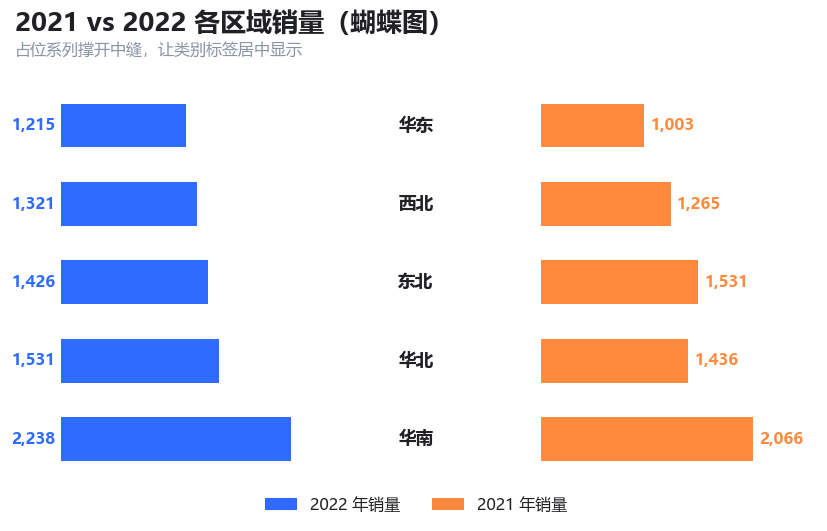

In [7]:
df6 = pd.DataFrame({
    '区域': ['华东', '西北', '东北', '华北', '华南'],
    '占位1': [2238, 2132, 2027, 1922, 1215],
    '2022年销量': [1215, 1321, 1426, 1531, 2238],
    '占位2': [1215] * 5,
    '2021年销量': [1003, 1265, 1531, 1436, 2066],
})
C22, C21 = '#2F6BFF', '#FF8A3D'

fig, ax = plt.subplots(figsize=(9.4, 5.0))
y = np.arange(len(df6))
lim = 3900
ax.set_xlim(-lim, lim)
ax.set_ylim(-0.7, len(df6) - 0.3)
ax.invert_yaxis()          # 让第一行数据出现在顶部，符合阅读顺序

for i, row in df6.iterrows():
    # 左侧：占位 + 2022
    ax.barh(i, -row['占位1'], height=0.56, color='none', edgecolor='none')
    ax.barh(i, -row['2022年销量'], left=-row['占位1'], height=0.56, color=C22, zorder=3)
    # 右侧：占位 + 2021
    ax.barh(i, row['占位2'], height=0.56, color='none', edgecolor='none')
    ax.barh(i, row['2021年销量'], left=row['占位2'], height=0.56, color=C21, zorder=3)

    ax.text(-row['占位1'] - row['2022年销量'] - 60, i, f'{row["2022年销量"]:,}',
            ha='right', va='center', fontsize=10.5, fontweight='bold', color=C22)
    ax.text(row['占位2'] + row['2021年销量'] + 60, i, f'{row["2021年销量"]:,}',
            ha='left', va='center', fontsize=10.5, fontweight='bold', color=C21)
    ax.text(0, i, row['区域'], ha='center', va='center', fontsize=11.5,
            fontweight='bold', color='#202124',
            bbox=dict(boxstyle='round,pad=0.32', fc='white', ec='none'))

ax.set_yticks([])
ax.set_xticks([])
clean_ax(ax, grid=None, left=False, bottom=False)
ax.legend(handles=[Patch(fc=C22, label='2022 年销量'), Patch(fc=C21, label='2021 年销量')],
          loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False, fontsize=10.5)
titles(ax, '2021 vs 2022 各区域销量（蝴蝶图）', '占位系列撑开中缝，让类别标签居中显示', pad=26)
finish(fig, 'case06_butterfly_placeholder')

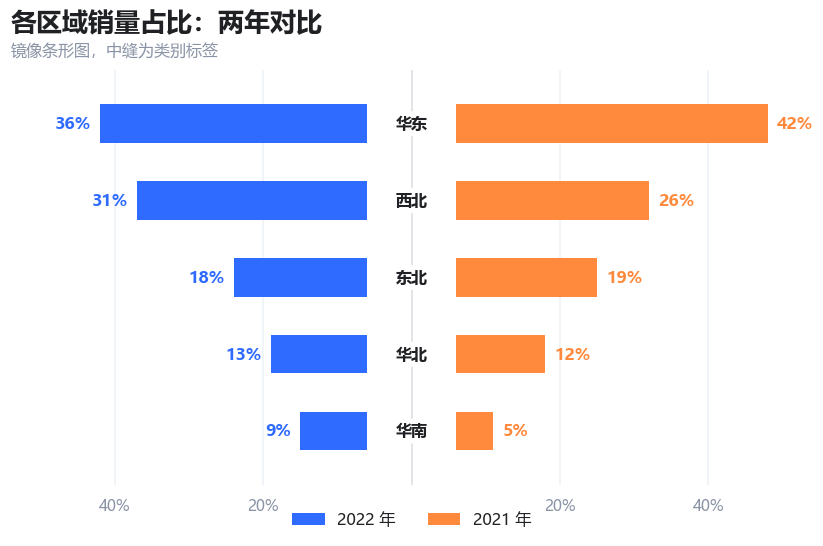

In [8]:
df7 = pd.DataFrame({'区域': ['华东', '西北', '东北', '华北', '华南'],
                    '2022年': [0.36, 0.31, 0.18, 0.13, 0.09],
                    '2021年': [0.42, 0.26, 0.19, 0.12, 0.05]})

fig, ax = plt.subplots(figsize=(9.4, 4.9))
y = np.arange(len(df7))
GAP = 0.06                 # 中缝半宽
ax.set_xlim(-0.54, 0.54)
ax.set_ylim(-0.7, len(df7) - 0.3)
ax.invert_yaxis()

for i, row in df7.iterrows():
    ax.barh(i, -row['2022年'], left=-GAP, height=0.5, color=C22, zorder=3)
    ax.barh(i, row['2021年'], left=GAP, height=0.5, color=C21, zorder=3)
    ax.text(-GAP - row['2022年'] - 0.012, i, f'{row["2022年"]:.0%}', ha='right', va='center',
            fontsize=11, fontweight='bold', color=C22)
    ax.text(GAP + row['2021年'] + 0.012, i, f'{row["2021年"]:.0%}', ha='left', va='center',
            fontsize=11, fontweight='bold', color=C21)
    ax.text(0, i, row['区域'], ha='center', va='center', fontsize=10.5,
            fontweight='bold', bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none'))

ax.axvline(0, color='#DADCE0', lw=1, zorder=1)
ax.set_yticks([])
ax.set_xticks([-0.4, -0.2, 0.2, 0.4])
ax.set_xticklabels(['40%', '20%', '20%', '40%'], fontsize=10, color=C_SUB)
clean_ax(ax, grid='x', left=False, bottom=False)
ax.legend(handles=[Patch(fc=C22, label='2022 年'), Patch(fc=C21, label='2021 年')],
          loc='lower center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=10.5)
titles(ax, '各区域销量占比：两年对比', '镜像条形图，中缝为类别标签', pad=26)
finish(fig, 'case07_butterfly_percent')

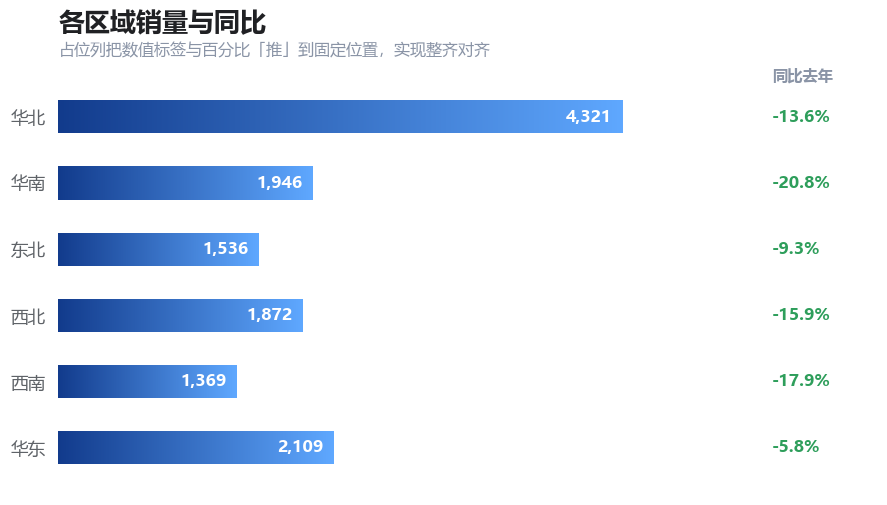

In [9]:
df8 = pd.DataFrame({'区域': ['华北', '华南', '东北', '西北', '西南', '华东'],
                    '销量': [4321, 1946, 1536, 1872, 1369, 2109],
                    '占位1': [0, 2375, 2785, 2449, 2952, 2212],
                    '占位2': 1080.25,
                    '同比去年': [-0.136, -0.208, -0.093, -0.159, -0.179, -0.058]})

fig, ax = plt.subplots(figsize=(9.6, 5.0))
y = np.arange(len(df8))
total = 4321 + 1080.25
ax.set_xlim(0, total * 1.16)
ax.set_ylim(-0.7, len(df8) - 0.3)
ax.invert_yaxis()

for i, row in df8.iterrows():
    hbar_gradient(ax, i, row['销量'], left=0, h=0.5, c1='#123B8C', c2='#5FA8FF')
    ax.barh(i, row['占位1'], left=row['销量'], height=0.5, color='none', edgecolor='none')
    ax.barh(i, row['占位2'], left=row['销量'] + row['占位1'], height=0.5, color='none', edgecolor='none')
    ax.text(row['销量'] - 80, i, f'{row["销量"]:,}', ha='right', va='center',
            fontsize=11, fontweight='bold', color='white', zorder=5)
    ax.text(total + 60, i, f'{row["同比去年"]:+.1%}', ha='left', va='center',
            fontsize=11, fontweight='bold',
            color='#2E9E5B' if row['同比去年'] < 0 else '#D93025')

ax.set_yticks(y)
ax.set_yticklabels(df8['区域'], fontsize=11.5)
ax.set_xticks([])
ax.tick_params(axis='y', length=0, pad=6)
clean_ax(ax, grid=None, left=False, bottom=False)
ax.text(total + 60, -0.62, '同比去年', ha='left', va='center',
        fontsize=10, color=C_SUB, fontweight='bold')
titles(ax, '各区域销量与同比', '占位列把数值标签与百分比「推」到固定位置，实现整齐对齐', pad=26)
finish(fig, 'case08_label_aligned_bar')